[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/notebooks/07_sql_for_data_analysis.ipynb)

<div dir="rtl">

# جلسه ۷: SQL کاربردی برای تحلیل داده

**اهداف این جلسه**

- آشنایی با پایگاه داده‌ی رابطه‌ای: جدول، کلید اصلی و کلید خارجی
- اجرای SQL از پایتون با `sqlite3` و دریافت نتیجه به‌صورت `DataFrame`
- `SELECT`، `WHERE`، `ORDER BY` و `LIMIT`
- تجمیع با `GROUP BY` و `HAVING`
- ادغام جدول‌ها با `JOIN`
- زیرپرسش (Subquery) و `WITH` (CTE)
- `CASE WHEN` و توابع پنجره‌ای (Window Functions)
- پرسش پارامتری و خطر **SQL Injection**
- ذخیره‌ی یک `DataFrame` در پایگاه داده

بیشتر داده‌های سازمانی در پایگاه داده‌های رابطه‌ای ذخیره می‌شوند و SQL زبان مشترک کار با آن‌هاست. در تقریباً همه‌ی مصاحبه‌های شغلی تحلیل داده، SQL پرسیده می‌شود.

</div>

<div dir="rtl">

## ۱. پایگاه داده‌ی Chinook

Chinook پایگاه داده‌ی یک فروشگاه آنلاین موسیقی است. جدول‌های اصلی و ارتباطشان:

```
Artist ──< Album ──< Track >── Genre
                       │
                       ^
Customer ──< Invoice ──< InvoiceLine
    │
    └── SupportRepId ──> Employee
```

- **کلید اصلی (Primary Key)**: ستونی که هر سطر را یکتا مشخص می‌کند، مثل `CustomerId` در جدول `Customer`.
- **کلید خارجی (Foreign Key)**: ستونی که به کلید اصلی جدول دیگری اشاره می‌کند، مثل `CustomerId` در جدول `Invoice`.
- `──<` یعنی رابطه‌ی یک به چند: هر مشتری چند فاکتور دارد و هر فاکتور چند قلم.

SQLite یک پایگاه داده‌ی کامل در قالب **یک فایل** است و در خود پایتون وجود دارد؛ نیازی به نصب سرور نیست. همه‌ی دستورهایی که اینجا یاد می‌گیریم، تقریباً بدون تغییر در PostgreSQL، MySQL و SQL Server هم کار می‌کنند.

</div>

In [1]:
import sqlite3
import urllib.request
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

db_path = Path("chinook.sqlite")
if not db_path.exists():
    urllib.request.urlretrieve(DATA_URL + "chinook.sqlite", db_path)

conn = sqlite3.connect(db_path)

def sql(query, params=None):
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql_query(query, conn, params=params)

sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


<div dir="rtl">

## ۲. `SELECT`: انتخاب ستون‌ها

ساختار پایه: `SELECT ستون‌ها FROM جدول`. با `AS` می‌توان نام ستون خروجی را تغییر داد و با `LIMIT` تعداد سطرها را محدود کرد.

> به ترتیب **نوشتن** دستورها دقت کنید: `SELECT → FROM → WHERE → GROUP BY → HAVING → ORDER BY → LIMIT`

</div>

In [2]:
sql("""
SELECT FirstName, LastName, Country, Email
FROM Customer
LIMIT 5
""")

,FirstName,LastName,Country,Email
0,Luís,Gonçalves,Brazil,luisg@embraer.com.br
1,Leonie,Köhler,Germany,leonekohler@surfeu.de
2,François,Tremblay,Canada,ftremblay@gmail.com
3,Bjørn,Hansen,Norway,bjorn.hansen@yahoo.no
4,František,Wichterlová,Czech Republic,frantisekw@jetbrains.com


In [3]:
sql("""
SELECT Name,
       Milliseconds / 60000.0 AS minutes,
       UnitPrice
FROM Track
LIMIT 5
""")

,Name,minutes,UnitPrice
0,For Those About To Rock (We Salute You),5.728650,0.99
1,Balls to the Wall,5.709367,0.99
2,Fast As a Shark,3.843650,0.99
3,Restless and Wild,4.200850,0.99
4,Princess of the Dawn,6.256967,0.99


<div dir="rtl">

## ۳. `WHERE`، `ORDER BY` و `DISTINCT`

- `WHERE` سطرها را فیلتر می‌کند. عملگرها: `=`، `<>`، `<`، `>`، `BETWEEN`، `IN`، `LIKE`، `IS NULL`
- `LIKE` با `%` (هر تعداد کاراکتر) و `_` (یک کاراکتر) برای جست‌وجوی الگوی متنی است.
- `ORDER BY ... DESC` مرتب‌سازی نزولی
- `DISTINCT` حذف سطرهای تکراری از خروجی

</div>

In [4]:
sql("""
SELECT Name, Composer, Milliseconds / 60000.0 AS minutes
FROM Track
WHERE Composer LIKE '%Mercury%'
  AND Milliseconds > 300000
ORDER BY minutes DESC
""")

,Name,Composer,minutes
0,Bohemian Rhapsody,"Mercury, Freddie",5.982467


In [5]:
sql("""
SELECT DISTINCT Country, State
FROM Customer
WHERE Country IN ('USA', 'Canada', 'Brazil')
  AND State IS NOT NULL
ORDER BY Country, State
""")

,Country,State
0,Brazil,DF
1,Brazil,RJ
2,Brazil,SP
3,Canada,AB
4,Canada,BC
5,Canada,MB
6,Canada,NS
7,Canada,NT
8,Canada,ON
9,Canada,QC


<div dir="rtl">

## ۴. تجمیع: `GROUP BY` و `HAVING`

توابع تجمیع: `COUNT`، `SUM`، `AVG`، `MIN`، `MAX`. این همان `groupby` در Pandas است.

- `WHERE` سطرها را **قبل** از گروه‌بندی فیلتر می‌کند.
- `HAVING` گروه‌ها را **بعد** از گروه‌بندی فیلتر می‌کند.

</div>

In [6]:
sql("""
SELECT BillingCountry   AS country,
       COUNT(*)         AS invoices,
       ROUND(SUM(Total), 2) AS revenue,
       ROUND(AVG(Total), 2) AS avg_invoice
FROM Invoice
GROUP BY BillingCountry
HAVING COUNT(*) >= 10
ORDER BY revenue DESC
""")

,country,invoices,revenue,avg_invoice
0,USA,91,523.06,5.75
1,Canada,56,303.96,5.43
2,France,35,195.10,5.57
3,Brazil,35,190.10,5.43
4,Germany,28,156.48,5.59
5,United Kingdom,21,112.86,5.37
6,Czech Republic,14,90.24,6.45
7,Portugal,14,77.24,5.52
8,India,13,75.26,5.79


<div dir="rtl">

## ۵. `JOIN`: ترکیب جدول‌ها

نام آهنگ در `Track` است، نام سبک در `Genre`. برای داشتن هر دو، جدول‌ها را روی کلید مشترک ادغام می‌کنیم. استفاده از نام مستعار کوتاه برای جدول‌ها (`t`، `g`) کد را خوانا می‌کند.

- `INNER JOIN` (یا فقط `JOIN`): فقط سطرهای دارای تطابق در هر دو جدول
- `LEFT JOIN`: همه‌ی سطرهای جدول چپ، حتی بدون تطابق

</div>

In [7]:
sql("""
SELECT t.Name AS track, ar.Name AS artist, al.Title AS album, g.Name AS genre
FROM Track AS t
JOIN Album  AS al ON t.AlbumId  = al.AlbumId
JOIN Artist AS ar ON al.ArtistId = ar.ArtistId
JOIN Genre  AS g  ON t.GenreId  = g.GenreId
LIMIT 5
""")

,track,artist,album,genre
0,For Those About To Rock (We Salute You),AC/DC,For Those About To Rock We Salute You,Rock
1,Balls to the Wall,Accept,Balls to the Wall,Rock
2,Fast As a Shark,Accept,Restless and Wild,Rock
3,Restless and Wild,Accept,Restless and Wild,Rock
4,Princess of the Dawn,Accept,Restless and Wild,Rock


<div dir="rtl">

**سؤال کسب‌وکاری:** فروش هر سبک موسیقی چقدر بوده است؟ برای این کار باید از `InvoiceLine` (فروش) به `Track` و از آنجا به `Genre` برسیم:

</div>

In [8]:
genre_sales = sql("""
SELECT g.Name AS genre,
       SUM(il.Quantity)                 AS tracks_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine AS il
JOIN Track AS t ON il.TrackId = t.TrackId
JOIN Genre AS g ON t.GenreId  = g.GenreId
GROUP BY g.Name
ORDER BY revenue DESC
""")
genre_sales.head(10)

,genre,tracks_sold,revenue
0,Rock,835,826.65
1,Latin,386,382.14
2,Metal,264,261.36
3,Alternative & Punk,244,241.56
4,TV Shows,47,93.53
5,Jazz,80,79.20
6,Blues,61,60.39
7,Drama,29,57.71
8,R&B/Soul,41,40.59
9,Classical,41,40.59


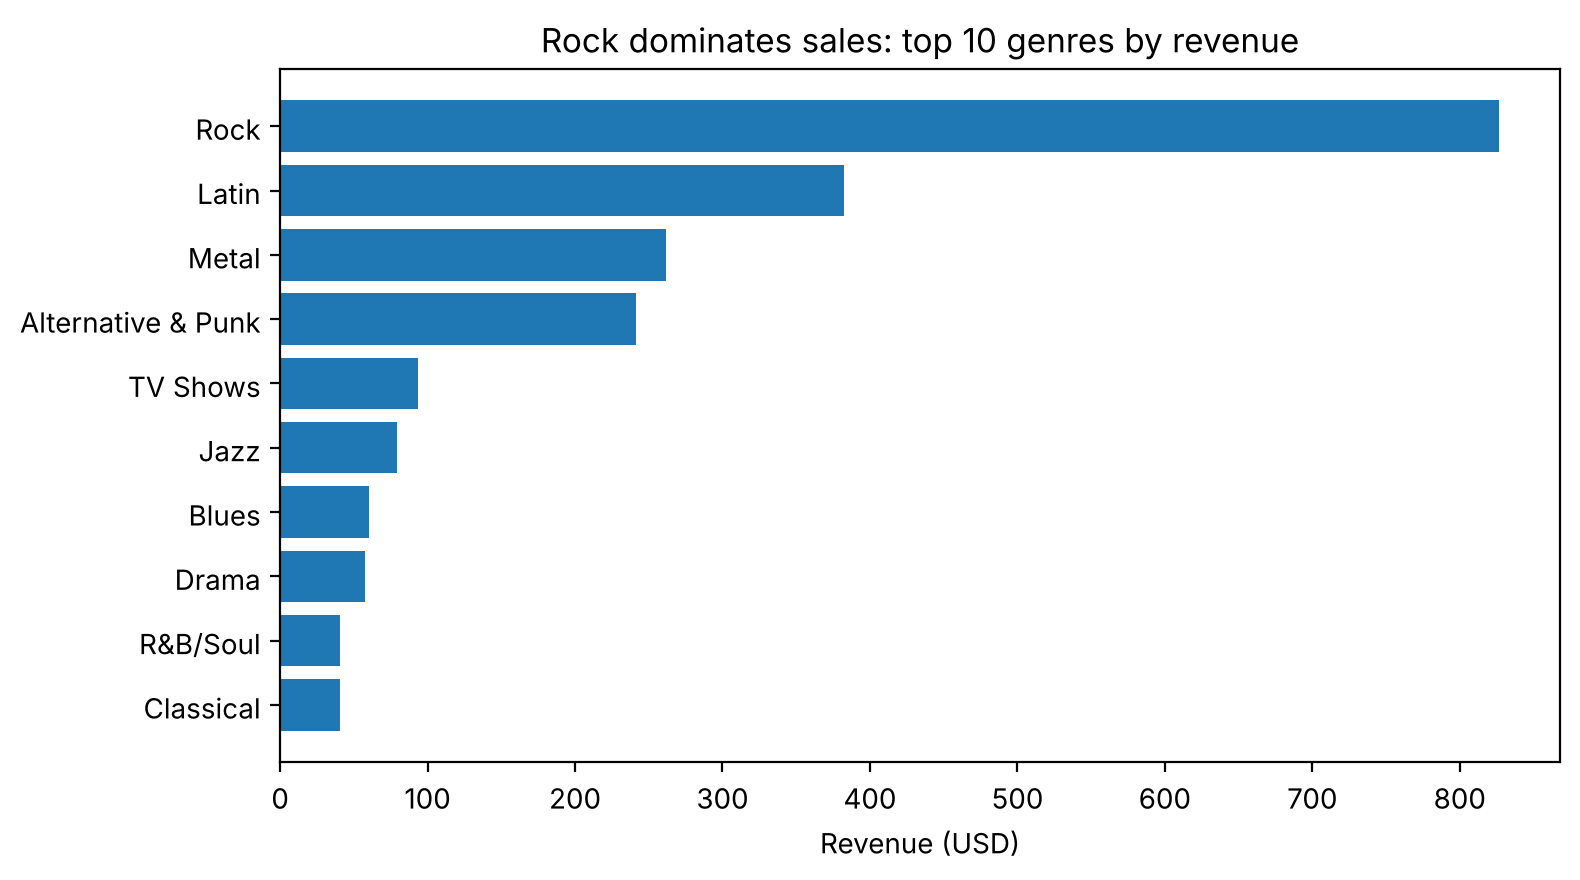

In [9]:
top = genre_sales.head(10).sort_values("revenue")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["genre"], top["revenue"], color="tab:blue")
ax.set_xlabel("Revenue (USD)")
ax.set_title("Rock dominates sales: top 10 genres by revenue")
plt.tight_layout()
plt.show()

<div dir="rtl">

### `LEFT JOIN` برای پیدا کردن «آنچه نیست»

کدام هنرمندها هیچ آهنگی نفروخته‌اند؟ با `LEFT JOIN`، هنرمندان بدون فروش هم در نتیجه می‌مانند و ستون‌های فروششان `NULL` می‌شود:

</div>

In [10]:
sql("""
SELECT COUNT(*) AS artists_without_sales
FROM Artist AS ar
LEFT JOIN Album       AS al ON ar.ArtistId = al.ArtistId
LEFT JOIN Track       AS t  ON al.AlbumId  = t.AlbumId
LEFT JOIN InvoiceLine AS il ON t.TrackId   = il.TrackId
GROUP BY ar.ArtistId
HAVING COUNT(il.InvoiceLineId) = 0
""").shape[0]

110

<div dir="rtl">

### Self Join: جدولی که به خودش اشاره می‌کند

در جدول `Employee`، ستون `ReportsTo` شناسه‌ی **مدیر** هر کارمند است که خودش هم در همین جدول است:

</div>

In [11]:
sql("""
SELECT e.FirstName || ' ' || e.LastName AS employee,
       e.Title,
       m.FirstName || ' ' || m.LastName AS manager
FROM Employee AS e
LEFT JOIN Employee AS m ON e.ReportsTo = m.EmployeeId
""")

,employee,Title,manager
0,Andrew Adams,General Manager,NaN
1,Nancy Edwards,Sales Manager,Andrew Adams
2,Jane Peacock,Sales Support Agent,Nancy Edwards
3,Margaret Park,Sales Support Agent,Nancy Edwards
4,Steve Johnson,Sales Support Agent,Nancy Edwards
5,Michael Mitchell,IT Manager,Andrew Adams
6,Robert King,IT Staff,Michael Mitchell
7,Laura Callahan,IT Staff,Michael Mitchell


<div dir="rtl">

## ۶. زیرپرسش و `WITH` (CTE)

گاهی برای جواب دادن به یک سؤال، اول باید جواب یک سؤال دیگر را داشته باشیم. مثلاً: «کدام مشتری‌ها بیشتر از **میانگین** خرید کرده‌اند؟»

**زیرپرسش**: یک `SELECT` داخل یک `SELECT` دیگر.

</div>

In [12]:
sql("""
SELECT CustomerId, ROUND(SUM(Total), 2) AS spent
FROM Invoice
GROUP BY CustomerId
HAVING SUM(Total) > (SELECT SUM(Total) * 1.0 / COUNT(DISTINCT CustomerId) FROM Invoice)
ORDER BY spent DESC
LIMIT 5
""")

,CustomerId,spent
0,6,49.62
1,26,47.62
2,57,46.62
3,45,45.62
4,46,45.62


<div dir="rtl">

وقتی پرسش پیچیده می‌شود، `WITH` (Common Table Expression) خوانایی را خیلی بیشتر می‌کند: هر مرحله یک نام دارد و می‌توان آن را مثل یک جدول موقت استفاده کرد.

</div>

In [13]:
sql("""
WITH customer_spend AS (
    SELECT c.CustomerId,
           c.FirstName || ' ' || c.LastName AS customer,
           c.Country,
           SUM(i.Total) AS spent
    FROM Customer AS c
    JOIN Invoice  AS i ON c.CustomerId = i.CustomerId
    GROUP BY c.CustomerId
),
country_avg AS (
    SELECT Country, AVG(spent) AS avg_spent
    FROM customer_spend
    GROUP BY Country
)
SELECT cs.customer, cs.Country,
       ROUND(cs.spent, 2) AS spent,
       ROUND(ca.avg_spent, 2) AS country_avg
FROM customer_spend AS cs
JOIN country_avg   AS ca ON cs.Country = ca.Country
WHERE cs.spent > ca.avg_spent * 1.1
ORDER BY cs.spent DESC
LIMIT 8
""")

,customer,Country,spent,country_avg
0,Richard Cunningham,USA,47.62,40.24
1,Fynn Zimmermann,Germany,43.62,39.12


<div dir="rtl">

## ۷. `CASE WHEN`: منطق شرطی

`CASE` معادل `if/else` در SQL است؛ مثلاً برای دسته‌بندی آهنگ‌ها بر اساس طول:

</div>

In [14]:
sql("""
SELECT CASE
           WHEN Milliseconds < 180000 THEN '1. short (< 3 min)'
           WHEN Milliseconds < 300000 THEN '2. medium (3-5 min)'
           WHEN Milliseconds < 600000 THEN '3. long (5-10 min)'
           ELSE '4. very long (> 10 min)'
       END AS length_group,
       COUNT(*) AS tracks
FROM Track
GROUP BY length_group
ORDER BY length_group
""")

,length_group,tracks
0,1. short (< 3 min),480
1,2. medium (3-5 min),1954
2,3. long (5-10 min),809
3,4. very long (> 10 min),260


<div dir="rtl">

## ۸. توابع پنجره‌ای (Window Functions)

`GROUP BY` سطرها را در هر گروه **جمع می‌کند** و یک سطر برمی‌گرداند. توابع پنجره‌ای محاسبه را روی گروه انجام می‌دهند اما **همه‌ی سطرها را نگه می‌دارند** (درست مثل `transform` در Pandas).

ساختار: `تابع() OVER (PARTITION BY ... ORDER BY ...)`

| تابع | کاربرد |
|---|---|
| `ROW_NUMBER()`، `RANK()` | رتبه‌بندی در هر گروه |
| `SUM() OVER (ORDER BY ...)` | جمع تجمعی |
| `LAG()`، `LEAD()` | مقدار سطر قبلی/بعدی (مثلاً برای محاسبه‌ی رشد) |

**مثال ۱:** پرفروش‌ترین سبک در هر کشور

</div>

In [15]:
sql("""
WITH country_genre AS (
    SELECT i.BillingCountry AS country, g.Name AS genre,
           SUM(il.UnitPrice * il.Quantity) AS revenue
    FROM Invoice     AS i
    JOIN InvoiceLine AS il ON i.InvoiceId = il.InvoiceId
    JOIN Track       AS t  ON il.TrackId  = t.TrackId
    JOIN Genre       AS g  ON t.GenreId   = g.GenreId
    GROUP BY country, genre
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY country ORDER BY revenue DESC) AS rnk
    FROM country_genre
)
SELECT country, genre, ROUND(revenue, 2) AS revenue
FROM ranked
WHERE rnk = 1 AND genre <> 'Rock'
ORDER BY revenue DESC
""")

,country,genre,revenue
0,Ireland,TV Shows,13.93
1,Sweden,Latin,11.88
2,Argentina,Alternative & Punk,8.91


<div dir="rtl">

در همه‌ی کشورها به‌جز کشورهای بالا، Rock پرفروش‌ترین سبک است.

**مثال ۲:** فروش سالانه، رشد نسبت به سال قبل و جمع تجمعی

</div>

In [16]:
yearly = sql("""
WITH y AS (
    SELECT strftime('%Y', InvoiceDate) AS year, SUM(Total) AS revenue
    FROM Invoice
    GROUP BY year
)
SELECT year,
       ROUND(revenue, 2) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY year))
                   / LAG(revenue) OVER (ORDER BY year), 1) AS growth_pct,
       ROUND(SUM(revenue) OVER (ORDER BY year), 2) AS cumulative
FROM y
ORDER BY year
""")
yearly

,year,revenue,growth_pct,cumulative
0,2021,449.46,NaN,449.46
1,2022,481.45,7.1,930.91
2,2023,469.58,-2.5,1400.49
3,2024,477.53,1.7,1878.02
4,2025,450.58,-5.6,2328.60


<div dir="rtl">

## ۹. پرسش پارامتری و SQL Injection

فرض کنید نام کشور را از کاربر می‌گیریم. **هرگز** ورودی کاربر را مستقیم داخل رشته‌ی SQL نچسبانید:

```python
country = input()
sql(f"SELECT * FROM Customer WHERE Country = '{country}'")   # DANGEROUS
```

اگر کاربر به‌جای نام کشور بنویسد `x' OR '1'='1`، شرط همیشه درست می‌شود و **همه‌ی** مشتری‌ها برگردانده می‌شوند. به این حمله **SQL Injection** می‌گویند و یکی از رایج‌ترین آسیب‌پذیری‌های امنیتی وب است.

راه درست: پرسش پارامتری با `?`. پایگاه داده مقدار را فقط به‌عنوان **داده** تفسیر می‌کند، نه کد.

</div>

In [17]:
malicious = "x' OR '1'='1"

unsafe = sql(f"SELECT COUNT(*) AS n FROM Customer WHERE Country = '{malicious}'")
safe = sql("SELECT COUNT(*) AS n FROM Customer WHERE Country = ?", params=(malicious,))
print("string formatting :", unsafe["n"].iloc[0], "rows  <- every customer leaked")
print("parameterised     :", safe["n"].iloc[0], "rows")

sql("SELECT FirstName, LastName, City FROM Customer WHERE Country = ?", params=("Germany",))

string formatting : 59 rows  <- every customer leaked
parameterised     : 0 rows


,FirstName,LastName,City
0,Leonie,Köhler,Stuttgart
1,Hannah,Schneider,Berlin
2,Fynn,Zimmermann,Frankfurt
3,Niklas,Schröder,Berlin


<div dir="rtl">

## ۱۰. SQL یا Pandas؟

هر دو یک کار را انجام می‌دهند. قاعده‌ی سرانگشتی: **فیلتر و تجمیع را تا جای ممکن در پایگاه داده انجام دهید** و فقط نتیجه‌ی کوچک را به پایتون بیاورید. پایگاه داده‌ی یک سازمان ممکن است میلیاردها سطر داشته باشد که در حافظه‌ی لپ‌تاپ جا نمی‌شود. بعد از آن، تحلیل آماری و نمودار را در Pandas انجام دهید.

همان پرسش «فروش هر کشور» با Pandas:

</div>

In [18]:
invoices = sql("SELECT * FROM Invoice")
pandas_result = (invoices.groupby("BillingCountry")["Total"]
                         .agg(invoices="count", revenue="sum")
                         .query("invoices >= 10")
                         .sort_values("revenue", ascending=False)
                         .round(2))
pandas_result.head()

,invoices,revenue
BillingCountry,,
USA,91,523.06
Canada,56,303.96
France,35,195.10
Brazil,35,190.10
Germany,28,156.48


<div dir="rtl">

### ذخیره‌ی DataFrame در پایگاه داده

`to_sql` یک `DataFrame` را به جدول تبدیل می‌کند. این برای ترکیب داده‌های فایلی با پایگاه داده، یا تمرین SQL روی داده‌ی خودمان مفید است. در اینجا داده‌ی سفارش‌های فروشگاه را در یک پایگاه داده‌ی **درون حافظه** (`:memory:`) می‌گذاریم:

</div>

In [19]:
shop = sqlite3.connect(":memory:")
pd.read_csv(DATA_URL + "orders_clean.csv").to_sql("orders", shop, index=False)
pd.read_csv(DATA_URL + "products.csv").to_sql("products", shop, index=False)

pd.read_sql_query("""
SELECT p.category,
       COUNT(*) AS orders,
       ROUND(AVG(o.rating), 2) AS avg_rating,
       ROUND(SUM(o.total_price) / 1000000.0, 1) AS revenue_million_toman
FROM orders AS o
JOIN products AS p ON o.product_id = p.product_id
GROUP BY p.category
ORDER BY revenue_million_toman DESC
""", shop)

,category,orders,avg_rating,revenue_million_toman
0,Electronics,279,4.03,1561.7
1,Home,220,3.91,662.6
2,Clothing,216,3.84,410.0
3,Grocery,250,3.91,398.3
4,Books,231,4.04,160.4


In [20]:
shop.close()
conn.close()

<div dir="rtl">

## جمع‌بندی

| SQL | Pandas |
|---|---|
| `SELECT a, b` | `df[["a", "b"]]` |
| `WHERE` | `df[cond]` یا `query` |
| `GROUP BY ... SUM()` | `groupby().sum()` |
| `HAVING` | فیلتر بعد از `groupby` |
| `JOIN` | `merge` |
| `ORDER BY ... LIMIT n` | `sort_values().head(n)` |
| `OVER (PARTITION BY ...)` | `groupby().transform()` |

- همیشه از پرسش پارامتری استفاده کنید.
- فیلتر و تجمیع سنگین را به پایگاه داده بسپارید.

## تمرین

1. ۵ آلبومی که بیشترین تعداد آهنگ را دارند، همراه با نام هنرمندشان پیدا کنید.
2. هر کارمند پشتیبانی (`SupportRepId` در جدول `Customer`) مسئول چند مشتری است و مجموع فروش مشتریانش چقدر است؟
3. میانگین طول آهنگ (به دقیقه) در هر سبک را حساب کنید و فقط سبک‌هایی با بیش از ۵۰ آهنگ را نشان دهید.
4. با `ROW_NUMBER()`، برای هر مشتری **اولین** فاکتورش را پیدا کنید. در هر ماه چند مشتری جدید داشته‌ایم؟
5. کدام آهنگ‌ها در هیچ Playlistی نیستند؟ (راهنما: `LEFT JOIN` با `PlaylistTrack` و `IS NULL`)
6. روی پایگاه داده‌ی فروشگاه (`shop`)، با تابع پنجره‌ای `LAG`، رشد ماهانه‌ی فروش را حساب کنید.

</div>